# 2. Data Understanding
We inspect the files, identify data-quality issues and explore customer
history. Relationships with the target are examined only in the development
period defined below.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 4)
pd.set_option("display.max_columns", 10)

## Load the data
Each row is a purchase occasion. `ID` identifies the purchase and
`customer_id` identifies the customer, who may appear more than once.

In [2]:
train = pd.read_csv("../data/raw/train.csv")
test = pd.read_csv("../data/raw/test.csv")
clientes = pd.read_csv("../data/raw/clientes.csv")
target = "repeat_purchase_90d"

print("Train:", train.shape)
print("Test:", test.shape)
print("Customers:", clientes.shape)

Train: (6534, 39)
Test: (986, 38)
Customers: (1143, 13)


In [3]:
train.head()

,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,...,warehouse,document_series,purchase_date,ID,random_noise
0,558.11,510.90,453.75,104.36,0.0,...,Final Excel Warehouse 1,Ctrl Z Series 2,2024-10-29,10000000,-0.660448
1,978.80,830.02,795.77,183.03,0.0,...,Final Excel Warehouse 1,Ctrl Z Series 1,2017-07-08,10000001,0.924510
2,10.33,12.00,8.40,1.93,0.0,...,Final Excel Warehouse 1,Ctrl Z Series 3,2019-03-19,10000002,-0.258730
3,856.83,696.61,696.61,160.22,0.0,...,Final Excel Warehouse 1,Ctrl Z Series 3,2018-11-10,10000003,1.448402
4,1616.10,1488.85,1313.90,302.20,0.0,...,Final Excel Warehouse 1,Ctrl Z Series 2,2021-11-30,10000004,-1.058890


In [4]:
clientes.head()

,customer_id,country_or_region,commercial_region,island,municipality,...,street,address,customer_type,company_name,customer_since_year
0,842570,Country CT11: Land of The Final Version,Region RG37: We Will See Later,NaN,NaN,...,NaN,Address AD1120: Cell Without a Home,NaN,Excel Is Not A Database Ltd 150,2018
1,770941,Country CT9: Land of The Final Version,NaN,NaN,NaN,...,NaN,Address AD62: Cell Without a Home,NaN,Excel Is Not A Database Ltd 1064,2021
2,827053,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,...,Street ST170: PowerPoint New Walk,Address AD449: Cell Without a Home,NaN,Excel Is Not A Database Ltd 113,2016
3,494648,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,...,NaN,Address AD454: Cell Without a Home,NaN,Excel Is Not A Database Ltd 430,2015
4,429291,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,...,NaN,Address AD453: Cell Without a Home,NaN,Excel Is Not A Database Ltd 673,2015


In [5]:
print("Repeated purchase IDs in train:", train["ID"].duplicated().sum())
print("Repeated purchase IDs in test:", test["ID"].duplicated().sum())
print("Repeated customer IDs in clientes:", clientes["customer_id"].duplicated().sum())
print("Target values:", train[target].unique())
print("Columns only in train:", train.columns.difference(test.columns).tolist())

Repeated purchase IDs in train: 0
Repeated purchase IDs in test: 0
Repeated customer IDs in clientes: 0
Target values: [1 0]
Columns only in train: ['repeat_purchase_90d']


The keys are unique in their respective files. Train has 6,534 purchases
and test has 986. The extra training column is the binary target.

## Variables and missing values
We compare storage types, distinct values and missingness before deciding
how to prepare each variable.

In [6]:
info = pd.DataFrame(index=train.columns)
info["type"] = train.dtypes
info["unique"] = train.nunique()
info["missing train (%)"] = train.isna().mean() * 100
info["missing test (%)"] = test.isna().mean() * 100
info.round(2)

,type,unique,missing train (%),missing test (%)
Total a Pagar,float64,6122,0.99,0.00
Total Bruto,float64,6038,0.99,0.00
Total Liquido,float64,6093,0.99,0.00
Total Imp_,float64,5406,0.99,0.00
Total Portes,float64,215,0.99,0.00
Total Desc_ Global,float64,109,0.99,0.00
Total Desc_ Linha,float64,3519,0.99,0.00
Custo,float64,5736,0.99,0.00
N_ Detalhes,float64,171,0.99,0.00
invoice_count_current_purchase,float64,5,0.99,0.00


## Duplicate and incomplete purchases
We exclude `ID` when checking exact duplicates, since each row has its own
ID. Other columns are still present at this point.

In [7]:
cols = train.columns.drop("ID")
dup = train.duplicated(subset=cols)
print("Exact duplicates excluding ID:", dup.sum())

df = train.loc[~dup].copy()
print("Rows after removing duplicates:", len(df))

Exact duplicates excluding ID: 10


Rows after removing duplicates: 6524


In [8]:
cols = train.columns.drop(["ID", "customer_id", target])
missing = df.loc[df["purchase_date"].isna(), cols]

print("Distinct rows without a date:", len(missing))
print("Observed purchase fields in these rows:", missing.notna().sum().sum())

Distinct rows without a date: 55
Observed purchase fields in these rows: 0


There are 10 exact duplicates. After removing them, 55 records have neither
a date nor any purchase information. We exclude these from the temporal
analysis; the original records remain in `data/raw/`. All test rows are kept.

## Customer information
Before joining, we check that the customer table covers the purchases.

In [9]:
print("Training customers:", train["customer_id"].nunique())
print("Test customers:", test["customer_id"].nunique())

new = test.loc[~test["customer_id"].isin(train["customer_id"])]
print("Test customers absent from train:", new["customer_id"].nunique())

print("Unmatched train rows:", (~train["customer_id"].isin(clientes["customer_id"])).sum())
print("Unmatched test rows:", (~test["customer_id"].isin(clientes["customer_id"])).sum())

Training customers: 610
Test customers: 206
Test customers absent from train: 22
Unmatched train rows: 0
Unmatched test rows: 0


In [10]:
info = pd.DataFrame(index=clientes.columns)
info["unique"] = clientes.nunique()
info["missing (%)"] = clientes.isna().mean() * 100
info.round(2)

,unique,missing (%)
customer_id,1143,0.00
country_or_region,11,0.00
commercial_region,37,9.97
island,10,50.57
municipality,183,13.91
city,417,47.77
postal_area,271,6.21
postal_code,828,14.87
street,511,52.32
address,1120,0.52


All purchases match the customer table. Test includes 22 new customers.
`customer_type` is entirely empty. Company name and address are identifying.
Street and postal code are shared geographic categories, not unique customer
IDs by definition; we initially exclude them because of their granularity,
cardinality and coverage. Broader geography is retained. The numeric codes
in the decorative labels do not represent distances.

## Dates and validation period
Test contains later purchases. We therefore reserve the latest approximately
20% of dated training purchases for validation, keeping each date together.
We also leave a 90-day gap so training outcomes are known before validation.
This is our proposed assessment protocol, not a requirement of the brief.

In [11]:
train["purchase_date"] = pd.to_datetime(train["purchase_date"])
test["purchase_date"] = pd.to_datetime(test["purchase_date"])
df["purchase_date"] = pd.to_datetime(df["purchase_date"])

print("Train:", train["purchase_date"].min(), "to", train["purchase_date"].max())
print("Test:", test["purchase_date"].min(), "to", test["purchase_date"].max())

Train: 2015-07-11 00:00:00 to 2025-02-15 00:00:00
Test: 2025-05-24 00:00:00 to 2026-10-06 00:00:00


In [12]:
cut = df["purchase_date"].quantile(0.8).normalize()
gap = cut - pd.Timedelta(days=90)

print("Validation starts:", cut.date())
print("90-day gap starts:", gap.date())
print("Days between supplied train and test:",
      (test["purchase_date"].min() - train["purchase_date"].max()).days)

Validation starts: 2023-06-17
90-day gap starts: 2023-03-19
Days between supplied train and test: 98


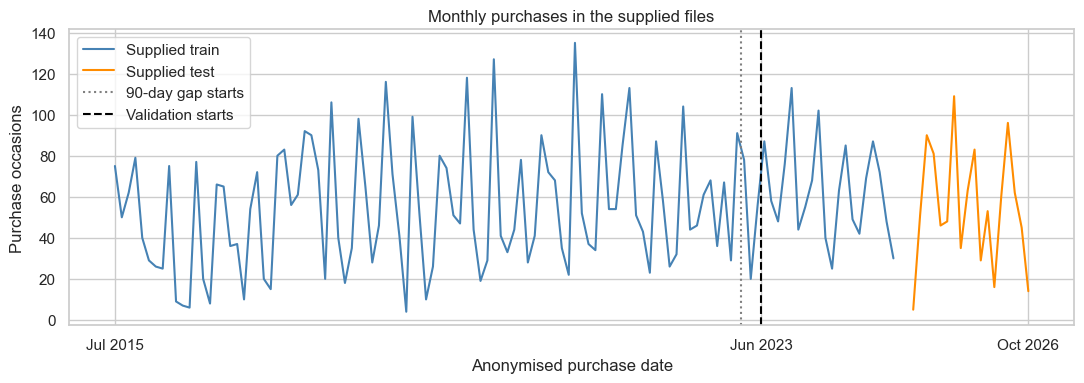

In [13]:
a = train.set_index("purchase_date").resample("MS").size()
b = test.set_index("purchase_date").resample("MS").size()

plt.figure(figsize=(11, 4))
plt.plot(a.index, a.values, label="Supplied train", color="steelblue")
plt.plot(b.index, b.values, label="Supplied test", color="darkorange")
plt.axvline(gap, color="grey", linestyle=":", label="90-day gap starts")
plt.axvline(cut, color="black", linestyle="--", label="Validation starts")
plt.xticks([a.index.min(), cut, b.index.max()],
           [a.index.min().strftime("%b %Y"), cut.strftime("%b %Y"),
            b.index.max().strftime("%b %Y")])
plt.title("Monthly purchases in the supplied files")
plt.xlabel("Anonymised purchase date")
plt.ylabel("Purchase occasions")
plt.legend()
plt.tight_layout()
plt.show()

In [14]:
print("Development rows:", (df["purchase_date"] < gap).sum())
print("Gap rows:", df["purchase_date"].between(gap, cut, inclusive="left").sum())
print("Validation rows:", (df["purchase_date"] >= cut).sum())

df = df.loc[df["purchase_date"] < gap].copy()
df = df.merge(clientes, on="customer_id", how="left", validate="many_to_one")

Development rows: 5024
Gap rows: 147
Validation rows: 1298


Validation starts on 17 June 2023. We have 5,024 development purchases,
147 in the gap and 1,298 for validation. The remaining target exploration
uses only development purchases.

Customers can appear in both periods, as the task includes future purchases
by existing customers. The earlier group notebook explored the full training
file, so this local holdout is not completely untouched.

## Target distribution

In [15]:
res = df[target].value_counts().sort_index()
print("Purchase counts:")
print(res)
print("\nClass shares (%):")
print((res / res.sum() * 100).round(2))
print("\nMajority-class accuracy reference:", round(res.max() / res.sum(), 4))

Purchase counts:
repeat_purchase_90d
0    2262
1    2762
Name: count, dtype: int64

Class shares (%):
repeat_purchase_90d
0    45.02
1    54.98
Name: count, dtype: float64

Majority-class accuracy reference: 0.5498


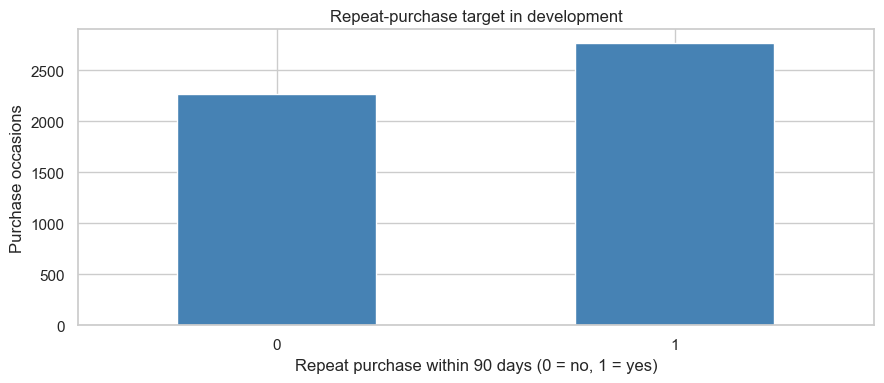

In [16]:
res.plot(kind="bar", color="steelblue", rot=0)
plt.title("Repeat-purchase target in development")
plt.xlabel("Repeat purchase within 90 days (0 = no, 1 = yes)")
plt.ylabel("Purchase occasions")
plt.tight_layout()
plt.show()

Repeat purchases represent 54.98% of development observations. Always
predicting this class would give about 55% accuracy. Both classes are well
represented; later models must improve on a baseline.

## Missing purchase history
A customer with no previous purchases cannot have an observed historical
mean price or gap between purchases. Such missing values are different
from measured zeros.

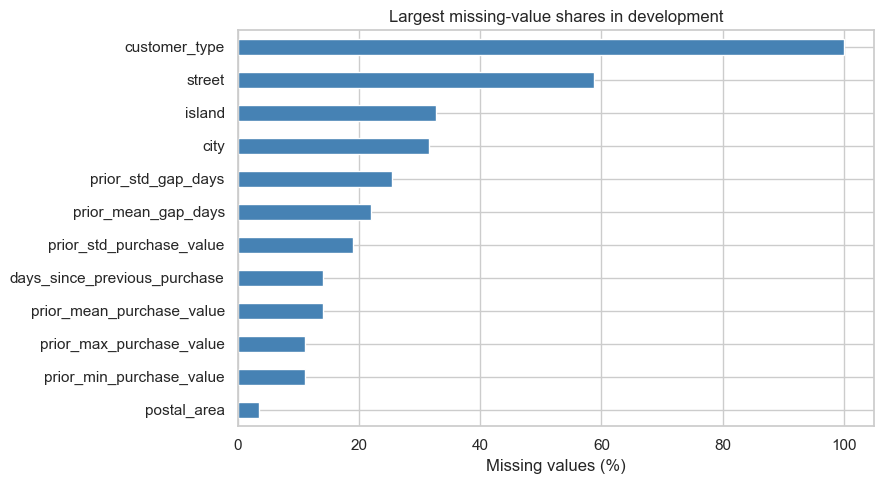

In [17]:
missing = df.drop(columns=target).isna().mean() * 100
missing = missing[missing > 0].sort_values().tail(12)

missing.plot(kind="barh", color="steelblue", figsize=(9, 5))
plt.title("Largest missing-value shares in development")
plt.xlabel("Missing values (%)")
plt.xlim(0, 105)
plt.tight_layout()
plt.show()

In [18]:
cols = ["days_since_previous_purchase", "prior_mean_purchase_value",
        "prior_std_purchase_value", "prior_mean_gap_days", "prior_std_gap_days"]
first = df["prior_purchase_count"] == 0

print("First-purchase observations:", first.sum())
res = pd.DataFrame(index=cols)
res["no previous purchases: missing (%)"] = df.loc[first, cols].isna().mean() * 100
res["previous purchases: missing (%)"] = df.loc[~first, cols].isna().mean() * 100
res.round(2)

First-purchase observations: 555


,no previous purchases: missing (%),previous purchases: missing (%)
days_since_previous_purchase,100.0,3.42
prior_mean_purchase_value,100.0,3.40
prior_std_purchase_value,100.0,8.93
prior_mean_gap_days,100.0,12.31
prior_std_gap_days,100.0,16.11


All five fields are missing for the 555 first purchases. Some returning
customers also have missing history. We can reconstruct a historical
average when total spend and purchase count are available. Remaining
numeric gaps receive development medians and missing-value flags.
Text gaps get a `Missing` category.

## Invalid values
Negative time gaps are impossible. Negative historical mean values and
annual spend conflict with the non-negative purchase values here.
Negative `random_noise` values are valid and will be kept.

In [19]:
cols = ["days_since_previous_purchase", "prior_mean_gap_days",
        "prior_mean_purchase_value", "spend_365d"]

print("Negative values in train:")
print((train[cols] < 0).sum())
print("\nNegative values in test:")
print((test[cols] < 0).sum())

Negative values in train:
days_since_previous_purchase    16
prior_mean_gap_days             16
prior_mean_purchase_value       16
spend_365d                      15
dtype: int64

Negative values in test:
days_since_previous_purchase    2
prior_mean_gap_days             2
prior_mean_purchase_value       2
spend_365d                      2
dtype: int64


In [20]:
cols = ["prior_mean_purchase_value", "spend_365d"]
print("Exact 1e9 values in train:")
print((train[cols] == 1_000_000_000).sum())
print("\nExact 1e9 values in test:")
print((test[cols] == 1_000_000_000).sum())

Exact 1e9 values in train:
prior_mean_purchase_value    16
spend_365d                   15
dtype: int64

Exact 1e9 values in test:
prior_mean_purchase_value    2
spend_365d                   2
dtype: int64


The repeated exact value 1,000,000,000 is treated as a suspected placeholder
in these two columns. This is an assumption based on the observed values;
it is not a documented missing-value code.

We also compare history summaries, allowing a 0.01 tolerance for rounding.

In [21]:
for name, data in [("train", train), ("test", test)]:
    low = data["prior_mean_purchase_value"] < data["prior_min_purchase_value"] - 0.01
    high = data["prior_mean_purchase_value"] > data["prior_max_purchase_value"] + 0.01
    print(name)
    print("Mean outside historical min/max:", (low | high).sum())

    low = data["spend_365d"] < data["spend_180d"] - 0.01
    high = data["spend_365d"] > data["prior_total_spend"] + 0.01
    print("Annual spend outside history bounds:", (low | high).sum())

    high = data["prior_max_purchase_value"] > data["prior_total_spend"] + 0.01
    print("Historical maximum above total spend:", high.sum())
    print()

train
Mean outside historical min/max: 77
Annual spend outside history bounds: 69
Historical maximum above total spend: 45

test
Mean outside historical min/max: 10
Annual spend outside history bounds: 11
Historical maximum above total spend: 6



## Treat inconsistent history values
Large amounts alone do not establish an error. We use relationships
between fields: historical mean equals total spend divided by purchase
count, annual spend cannot exceed all-time spend or fall below 180-day
spend, and the historical maximum cannot exceed all-time spend.

We first replace invalid negatives and the exact 1e9 values with
missing values. These are cell-level corrections; purchases are retained.

In [22]:
cols = ["days_since_previous_purchase", "prior_mean_gap_days",
        "prior_mean_purchase_value", "spend_365d"]
for col in cols:
    df.loc[df[col] < 0, col] = np.nan

for col in ["prior_mean_purchase_value", "spend_365d"]:
    df.loc[df[col] == 1_000_000_000, col] = np.nan

### Historical average
We compare the reported mean with total/count after excluding invalid
negatives and placeholders. When the count is zero, no historical
mean can be reconstructed.

In [23]:
mean = df["prior_total_spend"] / df["prior_purchase_count"].replace(0, np.nan)
known = df["prior_mean_purchase_value"].notna() & mean.notna()
bad = (df["prior_mean_purchase_value"] - mean).abs() > 0.01

print("Observed means checked:", known.sum())
print("Means agreeing with total/count:", (known & ~bad).sum())
print("Inconsistent means:", bad.sum())

Observed means checked: 4292
Means agreeing with total/count: 4262
Inconsistent means: 30


In [24]:
df.loc[bad, "prior_mean_purchase_value"] = np.nan
df["prior_mean_purchase_value"] = df["prior_mean_purchase_value"].fillna(mean)

### Historical maximum and annual spend
These values cannot be reconstructed exactly from the supplied columns.
We mark contradictory values as missing. We keep coherent extremes,
including large customers, rather than deleting their purchases.

In [25]:
bad = df["prior_max_purchase_value"] > df["prior_total_spend"] + 0.01
print("Inconsistent historical maxima:", bad.sum())
df.loc[bad, "prior_max_purchase_value"] = np.nan

low = df["spend_365d"] < df["spend_180d"] - 0.01
high = df["spend_365d"] > df["prior_total_spend"] + 0.01
print("Inconsistent annual spend:", (low | high).sum())
df.loc[low | high, "spend_365d"] = np.nan

Inconsistent historical maxima: 38
Inconsistent annual spend: 34


## Distributions after cleaning
The following summaries use corrected development data. Log scales
make coherent monetary tails easier to inspect.

In [26]:
cols = ["Total a Pagar", "prior_total_spend",
        "days_since_previous_purchase", "prior_purchase_count"]
df[cols].describe().round(2)

,Total a Pagar,prior_total_spend,days_since_previous_purchase,prior_purchase_count
count,5024.00,5024.00,4305.00,5024.00
mean,837.78,14355.66,100.15,20.16
std,1174.71,22711.41,155.50,36.07
min,0.93,0.00,1.00,0.00
25%,172.84,1101.84,15.00,2.00
50%,435.60,5202.23,57.00,8.00
75%,1001.74,16942.27,119.00,22.00
max,14433.41,196270.66,2324.00,262.00


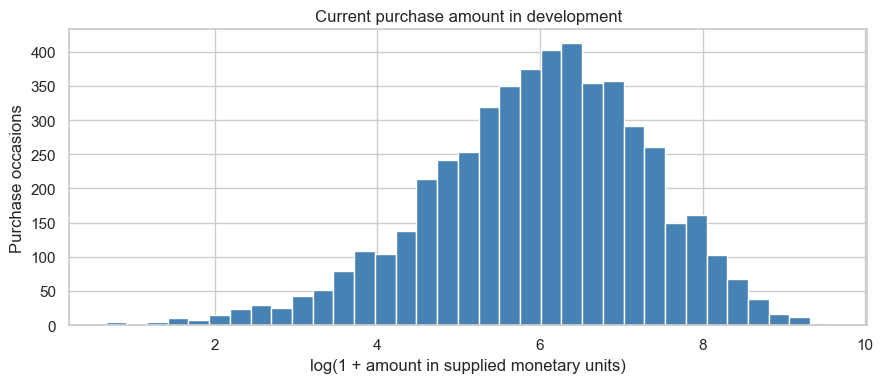

In [27]:
np.log1p(df["Total a Pagar"]).hist(bins=35, color="steelblue", edgecolor="white")
plt.title("Current purchase amount in development")
plt.xlabel("log(1 + amount in supplied monetary units)")
plt.ylabel("Purchase occasions")
plt.tight_layout()
plt.show()

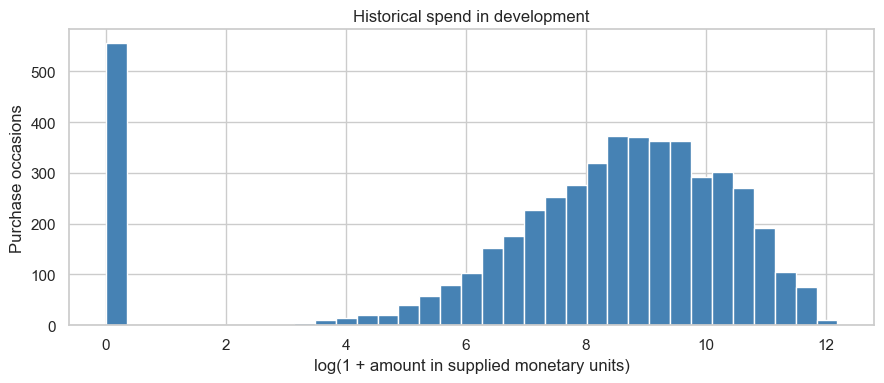

In [28]:
np.log1p(df["prior_total_spend"]).hist(bins=35, color="steelblue", edgecolor="white")
plt.title("Historical spend in development")
plt.xlabel("log(1 + amount in supplied monetary units)")
plt.ylabel("Purchase occasions")
plt.tight_layout()
plt.show()

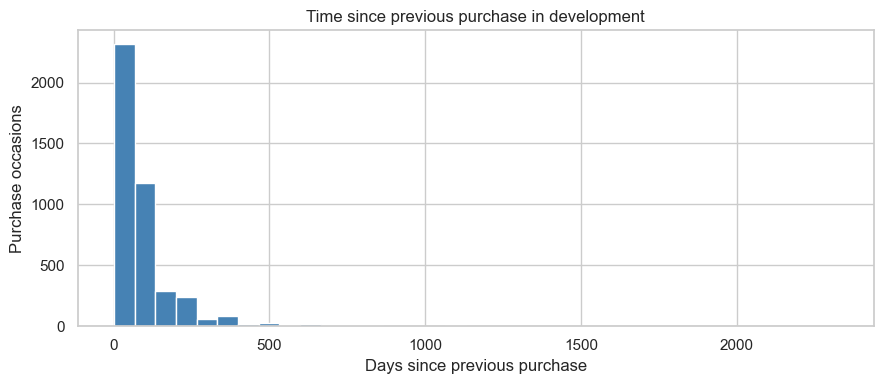

In [29]:
df["days_since_previous_purchase"].hist(bins=35, color="steelblue", edgecolor="white")
plt.title("Time since previous purchase in development")
plt.xlabel("Days since previous purchase")
plt.ylabel("Purchase occasions")
plt.tight_layout()
plt.show()

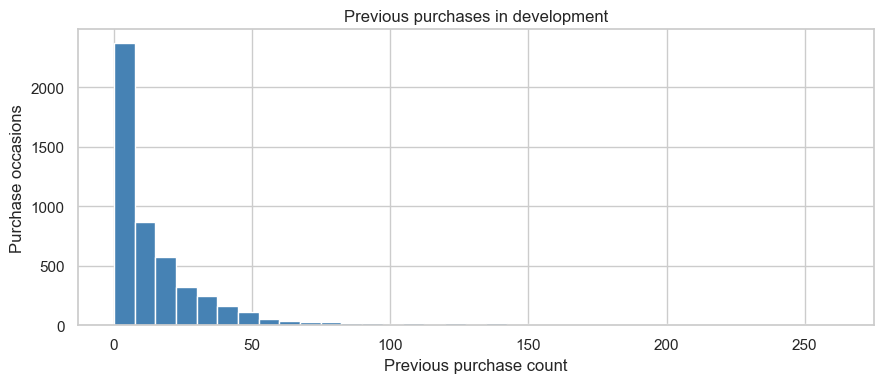

In [30]:
df["prior_purchase_count"].hist(bins=35, color="steelblue", edgecolor="white")
plt.title("Previous purchases in development")
plt.xlabel("Previous purchase count")
plt.ylabel("Purchase occasions")
plt.tight_layout()
plt.show()

Amounts and purchase counts have long right tails. A large purchase
can be valid, so we do not remove rows using a generic IQR threshold.
We will apply `log1p` to monetary inputs, then `StandardScaler` to the
numeric inputs, using development data only.

`Total Portes`, `Total Desc_ Global` and
`invoice_count_current_purchase` have zero interquartile range but
nonzero standard deviation. Standard scaling also handles these fields.

## Recency and repeat purchases
We divide recency into quartiles and compare the target rate. Missing
recency values do not enter these groups. Counts accompany the rates.

In [31]:
bins = pd.qcut(df["days_since_previous_purchase"], 4, duplicates="drop")
res = df.groupby(bins, observed=True)[target].agg(["size", "mean"])
res.columns = ["purchases", "repeat purchase (%)"]
res["repeat purchase (%)"] = res["repeat purchase (%)"] * 100
res.round(2)

,purchases,repeat purchase (%)
days_since_previous_purchase,,
"(0.999, 15.0]",1092,75.27
"(15.0, 57.0]",1087,66.70
"(57.0, 119.0]",1111,52.75
"(119.0, 2324.0]",1015,34.58


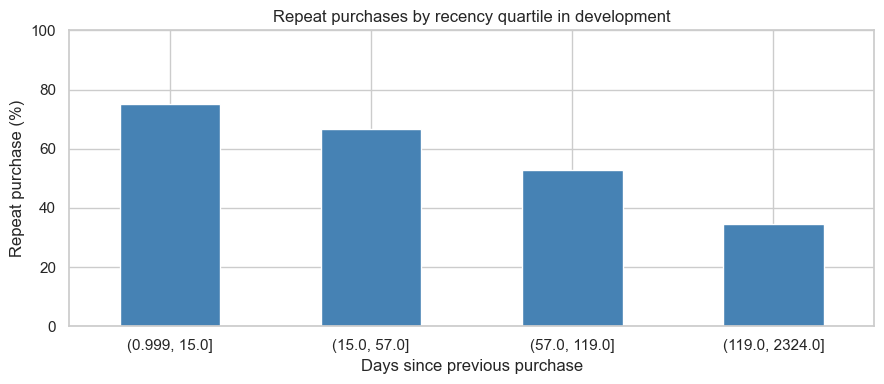

In [32]:
res["repeat purchase (%)"].plot(kind="bar", color="steelblue", rot=0)
plt.title("Repeat purchases by recency quartile in development")
plt.xlabel("Days since previous purchase")
plt.ylabel("Repeat purchase (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

The repeat-purchase rate falls from about 75% to 35% across the recency
quartiles. Customers who purchased more recently tend to buy again.

## Purchase frequency and repeat purchases

In [33]:
bins = pd.qcut(df["prior_purchase_count"], 4, duplicates="drop")
res = df.groupby(bins, observed=True)[target].agg(["size", "mean"])
res.columns = ["purchases", "repeat purchase (%)"]
res["repeat purchase (%)"] = res["repeat purchase (%)"] * 100
res.round(2)

,purchases,repeat purchase (%)
prior_purchase_count,,
"(-0.001, 2.0]",1275,36.63
"(2.0, 8.0]",1249,46.04
"(8.0, 22.0]",1280,56.25
"(22.0, 262.0]",1220,81.97


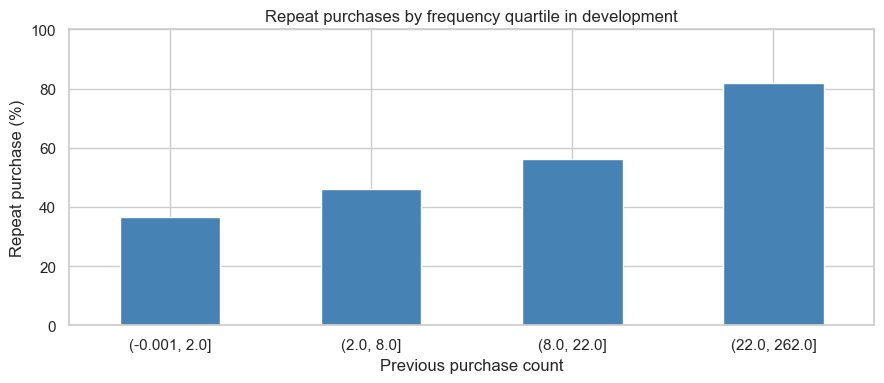

In [34]:
res["repeat purchase (%)"].plot(kind="bar", color="steelblue", rot=0)
plt.title("Repeat purchases by frequency quartile in development")
plt.xlabel("Previous purchase count")
plt.ylabel("Repeat purchase (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

Repeat-purchase rates rise from about 37% to 82% across the frequency
quartiles. These are associations at purchase level, with repeated customers;
they do not establish causality or determine the final feature selection.

## Payment categories
We examine the six most frequent categories, showing both purchase counts
and distinct customers.

In [35]:
group = df["payment_type"].fillna("Missing")
res = df.groupby(group)[target].agg(["size", "mean"])
res.columns = ["purchases", "repeat purchase (%)"]
res["repeat purchase (%)"] = res["repeat purchase (%)"] * 100
res["customers"] = df.groupby(group)["customer_id"].nunique()
res = res.sort_values("purchases", ascending=False).head(6)
res.round(2)

,purchases,repeat purchase (%),customers
payment_type,,,
Maybe Tomorrow Payment 7,3584,51.28,389
Maybe Tomorrow Payment 12,775,52.65,194
Maybe Tomorrow Payment 9,404,95.54,9
Missing,144,59.72,101
Maybe Tomorrow Payment 10,85,37.65,18
Maybe Tomorrow Payment 8,25,28.00,6


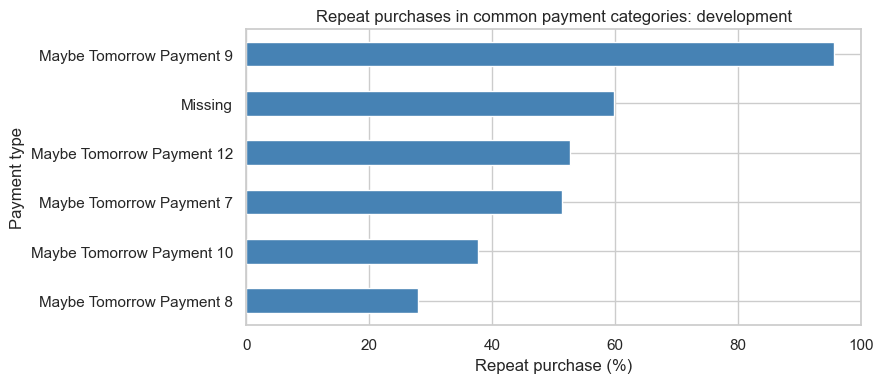

In [36]:
res = res.sort_values("repeat purchase (%)")
res["repeat purchase (%)"].plot(kind="barh", color="steelblue")
plt.title("Repeat purchases in common payment categories: development")
plt.xlabel("Repeat purchase (%)")
plt.ylabel("Payment type")
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

The table helps distinguish many purchases from many independent customers.
Category differences are candidates for later modelling, not a reason to
assume that payment method causes repeat purchases.

## Correlations and noise
We inspect a small set of history variables with Spearman correlation.
IDs are excluded because their numeric values do not measure customer behaviour.

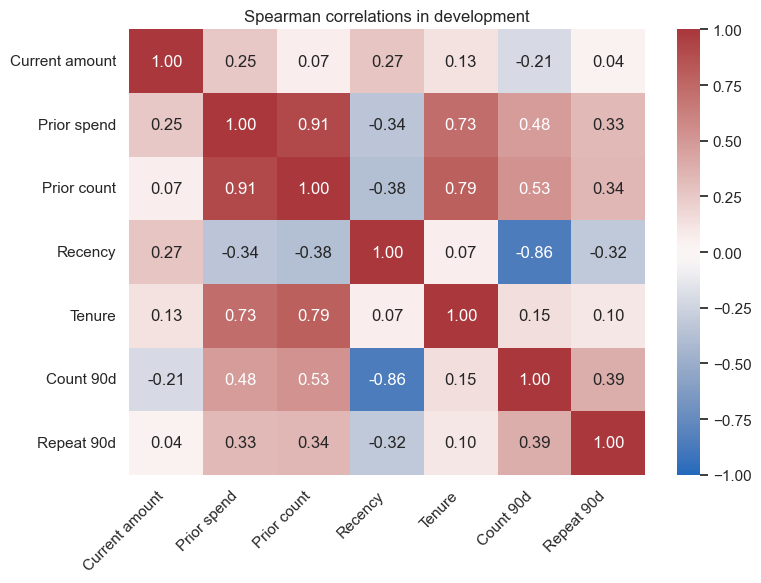

In [37]:
cols = ["Total a Pagar", "prior_total_spend", "prior_purchase_count",
        "days_since_previous_purchase", "customer_tenure_days",
        "purchase_count_90d", target]
labels = ["Current amount", "Prior spend", "Prior count", "Recency",
          "Tenure", "Count 90d", "Repeat 90d"]
corr = df[cols].corr(method="spearman")

plt.figure(figsize=(8, 6))
sns.heatmap(corr, vmin=-1, vmax=1, cmap="vlag", annot=True, fmt=".2f",
            xticklabels=labels, yticklabels=labels)
plt.title("Spearman correlations in development")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Previous spend and purchase count are strongly correlated (0.91), so they
may contain redundant information. Recent 90-day frequency has a stronger
association with the target (0.39) than current purchase amount (0.04).
Feature selection remains for the modelling stage.

In [38]:
df.groupby(target)["random_noise"].agg(["count", "mean", "std"]).round(3)

,count,mean,std
repeat_purchase_90d,,,
0,2262,-0.001,0.993
1,2762,-0.040,1.001


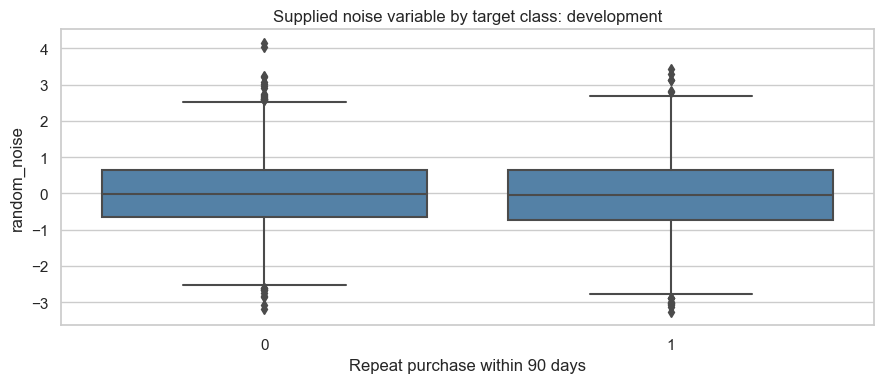

In [39]:
sns.boxplot(data=df, x=target, y="random_noise", color="steelblue")
plt.title("Supplied noise variable by target class: development")
plt.xlabel("Repeat purchase within 90 days")
plt.ylabel("random_noise")
plt.tight_layout()
plt.show()

We retain `random_noise` until feature selection. Similar distributions
alone do not prove the absence of every predictive relationship.

## Decisions for Data Preparation

- Remove exact duplicates and exclude undated, incomplete training rows.
- Join customer attributes and remove empty, identifying and selected granular fields.
- Use chronological development/validation periods with a 90-day gap.
- Replace invalid negatives and exact 1e9 values with missing values.
- Reconstruct missing or inconsistent historical averages from total/count.
- Treat inconsistent historical maximum and annual spend as missing values.
- Add numeric missing-value flags and fill remaining gaps with development medians.
- Retain coherent large amounts; apply log1p to monetary inputs and standardise.
- Encode categories, grouping those with fewer than 20 development purchases.
- Keep IDs for tracking and exclude them from model inputs.

Reconstructing averages assumes total spend and purchase count are
reliable. The near-universal agreement of the uncorrupted averages
with this formula supports that choice; it is not independent source
verification. Other invalid values are not assigned guessed amounts.
Calendar inputs are candidates for L1 selection. The rare-category
threshold is fixed at 20 for this homework; comparing thresholds and
calendar feature sets remains for the final project. The official Kaggle metric is **F1-Score**.

Next: [Data Preparation](03_Data_Preparation.ipynb).